<a href="https://colab.research.google.com/github/victorsanchezarevalo/Pymportx/blob/main/WGCNA_5xFAD_Colab_FIX(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 6 — WGCNA: redes de coexpresión en el modelo 5xFAD de Alzheimer

**Módulo de Transcriptómica — Máster en Bioinformática**

En esta práctica usamos **PyWGCNA** para construir una red de coexpresión génica sobre un RNA-seq del modelo murino de Alzheimer **5xFAD**:

- **192 muestras** de corteza e hipocampo
- **2 genotipos**: `5xFADWT` (control) y `5xFADHEMI` (modelo de Alzheimer)
- **4 edades**: 4, 8, 12 y 18 meses
- Ambos sexos

**Flujo de la práctica:**

1. Preprocesado de la matriz de expresión
2. Construcción de la red y detección de módulos (`findModules`)
3. Relación módulo–rasgo (*module-trait relationships*)
4. Genes hub de cada módulo
5. Visualización de redes de coexpresión
6. Enriquecimiento funcional de los módulos (GO/KEGG)
7. Interacciones proteína–proteína (STRING)

> **Concepto clave**: a diferencia del análisis de expresión diferencial (gen a gen), WGCNA agrupa genes en **módulos** de genes coexpresados y relaciona cada módulo (resumido por su *eigengene*) con los rasgos experimentales.

## 1. Instalación

Instalamos PyWGCNA y sus dependencias. Tarda 1–2 minutos.

> Si Colab muestra un aviso de que hay que **reiniciar la sesión** tras la instalación, hazlo (*Entorno de ejecución → Reiniciar sesión*) y continúa desde la celda siguiente (no hace falta reinstalar).

In [1]:
# PyWGCNA 2.2.1 no es compatible con pandas 3 -> fijamos pandas 2.3.3
!pip install -q "pandas==2.3.3" PyWGCNA
import importlib.metadata
print("PyWGCNA", importlib.metadata.version("PyWGCNA"), "| pandas", importlib.metadata.version("pandas"))
# Si pandas no es 2.3.3: Entorno de ejecucion -> Reiniciar sesion y ejecutar desde la celda de datos


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
PyWGCNA 2.2.1 | pandas 2.3.3


## 2. Datos

Los datos son los del tutorial oficial de PyWGCNA (artículo del modelo 5xFAD), incluidos en el repositorio del curso:

- `expressionList.csv.gz`: matriz de expresión (192 muestras × ~22.000 genes, valores tipo TPM)
- `sampleInfo.csv`: metadatos de las muestras (`Age`, `Tissue`, `Sex`, `Genotype`)
- `geneList`: tabla de equivalencia Ensembl → símbolo de gen (para no depender del servicio BioMart, que a veces falla)

In [2]:
import urllib.request
import gzip
import shutil
from pathlib import Path

DATA_DIR = Path("datos_5xFAD")
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/victorsanchezarevalo/transcriptomica-master/main/practicas/06-wgcna-5xfad/datos"
FICHEROS = ["expressionList.csv.gz", "sampleInfo.csv", "geneList"]

for f in FICHEROS:
    destino = DATA_DIR / f
    if not destino.exists():
        print(f"Descargando {f} ...")
        urllib.request.urlretrieve(f"{BASE_URL}/{f}", destino)
    print(f"{f}: {destino.stat().st_size / 1e6:.2f} MB")

# Descomprimir la matriz de expresión
gz = DATA_DIR / "expressionList.csv.gz"
csv = DATA_DIR / "expressionList.csv"
if not csv.exists():
    print("Descomprimiendo expressionList.csv.gz ...")
    with gzip.open(gz, "rb") as f_in, open(csv, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)
print(f"expressionList.csv: {csv.stat().st_size / 1e6:.1f} MB")
print("\nDatos listos.")

Descargando expressionList.csv.gz ...
expressionList.csv.gz: 10.97 MB
Descargando sampleInfo.csv ...
sampleInfo.csv: 0.01 MB
Descargando geneList ...
geneList: 2.67 MB
Descomprimiendo expressionList.csv.gz ...
expressionList.csv: 49.6 MB

Datos listos.


## 3. Crear el objeto PyWGCNA

El objeto `WGCNA` guarda la expresión en formato **AnnData**: filas/`obs` = muestras, columnas/`var` = genes.

In [3]:
import pandas as pd
import numpy as np
import PyWGCNA

pyWGCNA_5xFAD = PyWGCNA.WGCNA(
    name="5xFAD",
    species="mus musculus",
    geneExpPath=str(DATA_DIR / "expressionList.csv"),
    outputPath="PyWGCNA_output/",  # la barra final es necesaria en PyWGCNA 2.2.1
    save=True,
)

print(pyWGCNA_5xFAD.geneExpr)
pyWGCNA_5xFAD.geneExpr.to_df().iloc[:5, :5]

Saving data to be True, checking requirements ...
Figure directory does not exist!
Creating figure directory!
AnnData object with n_obs × n_vars = 192 × 55448
    layers: None (.X)


,ENSMUSG00000000003,ENSMUSG00000000028,ENSMUSG00000000031,ENSMUSG00000000037,ENSMUSG00000000049
sample_id,,,,,
X4mo_cortex_F_5xFADHEMI_430,0.0,1.90,0.00,0.13,0.43
X4mo_cortex_F_5xFADHEMI_431,0.0,1.10,0.06,0.07,0.18
X4mo_cortex_F_5xFADHEMI_433,0.0,1.18,0.07,0.13,1.90
X4mo_cortex_F_5xFADHEMI_434,0.0,2.18,0.00,0.07,0.31
X4mo_cortex_F_5xFADHEMI_511,0.0,1.50,0.10,0.14,0.53


## 4. Preprocesado

`preprocess()` elimina:

- genes con demasiados valores faltantes o **baja expresión** (por defecto, < 1 TPM en la mayoría de muestras)
- muestras con demasiados valores faltantes
- genes con **varianza cero**

Estos filtros se pueden ajustar con `TPMcutoff` y `cut`.

In [4]:
pyWGCNA_5xFAD.preprocess(show=False)
print("\nTras el preprocesado:")
print(pyWGCNA_5xFAD.datExpr)


Pre-processing...
	Detecting genes and samples with too many missing values...
	Done pre-processing..


Tras el preprocesado:
View of AnnData object with n_obs × n_vars = 192 × 23844
    layers: None (.X)


## 5. Selección de genes para la red

La matriz tiene **~55.000 genes**. Construir la red con todos requeriría una matriz de adyacencia de 55.000 × 55.000 (~25 GB de RAM) — inviable en Colab.

**Práctica estándar en WGCNA**: quedarse con los genes **más variables** entre muestras (los invariables no aportan información de coexpresión). Seleccionamos los **5.000 genes con mayor varianza**, lo que reduce la memoria a ~200 MB.

> En R/WGCNA se usa el mismo criterio (típicamente top 5000–10000 por MAD o varianza).

In [5]:
import gc

# 1. log2(TPM+1) ANTES de elegir genes (con TPM crudos las colas pesadas distorsionan las correlaciones)
pyWGCNA_5xFAD.datExpr.X = np.log2(pyWGCNA_5xFAD.datExpr.X + 1)

# 2. Top 5000 genes por varianza (sobre datExpr, ya preprocesado y en log2)
TOP_N = 5000
top_genes = pyWGCNA_5xFAD.datExpr.to_df().var(axis=0).nlargest(TOP_N).index
print(f"Genes seleccionados: {len(top_genes)} de {pyWGCNA_5xFAD.datExpr.shape[1]}")

# 3. Filtrar y sincronizar geneExpr con datExpr
pyWGCNA_5xFAD.datExpr = pyWGCNA_5xFAD.datExpr[:, top_genes].copy()
pyWGCNA_5xFAD.geneExpr = pyWGCNA_5xFAD.datExpr.copy()
gc.collect()
print(pyWGCNA_5xFAD.datExpr.shape, "max log2:", pyWGCNA_5xFAD.datExpr.X.max())


Genes seleccionados: 3000 de 23844
(192, 3000) max log2: 15.852851329486102


## 6. Construcción de la red y detección de módulos

`findModules()` ejecuta en una sola llamada todo el flujo clásico de WGCNA:

1. **Elección del soft-thresholding power (β)**: se escoge la potencia más baja que da una topología aproximadamente *scale-free*
2. Similitud de coexpresión y matriz de **adyacencia**
3. **TOM** (Topological Overlap Matrix)
4. Clustering jerárquico sobre la disimilitud TOM + corte dinámico del dendrograma
5. **Fusión** de módulos muy similares

Encontraréis los parámetros usados en `pyWGCNA_5xFAD.sft` (powers explorados) y los módulos asignados en `geneExpr.var['moduleColors']`.

> Esta celda puede tardar **varios minutos**. Es la parte pesada del análisis.

Run WGCNA...
pickSoftThreshold: calculating connectivity for given powers...
will use block size  3000
    Power  SFT.R.sq     slope truncated R.sq     mean(k)   median(k)  \
0       1  0.372324 -0.496762       0.317785  292.711782  299.190902   
1       2   0.48624 -0.573542       0.341817  123.309557  120.158144   
2       3  0.558167 -0.621779       0.476516   72.027051   58.701365   
3       4   0.57879 -0.693887       0.583345   48.499861      31.368   
4       5   0.68173 -0.727916       0.733345   35.163449   18.688963   
5       6  0.810251 -0.745435       0.896108   26.677406   12.118418   
6       7  0.857377 -0.818109       0.950355    20.88002    7.880531   
7       8  0.843889 -0.922551       0.961749   16.723577    5.237484   
8       9  0.844693 -1.012812       0.966551   13.636861    3.646994   
9      10  0.830343 -1.105485       0.957812   11.281892    2.750976   
10     11  0.847413 -1.187781       0.960866     9.44627    2.000005   
11     13  0.874681 -1.297172    

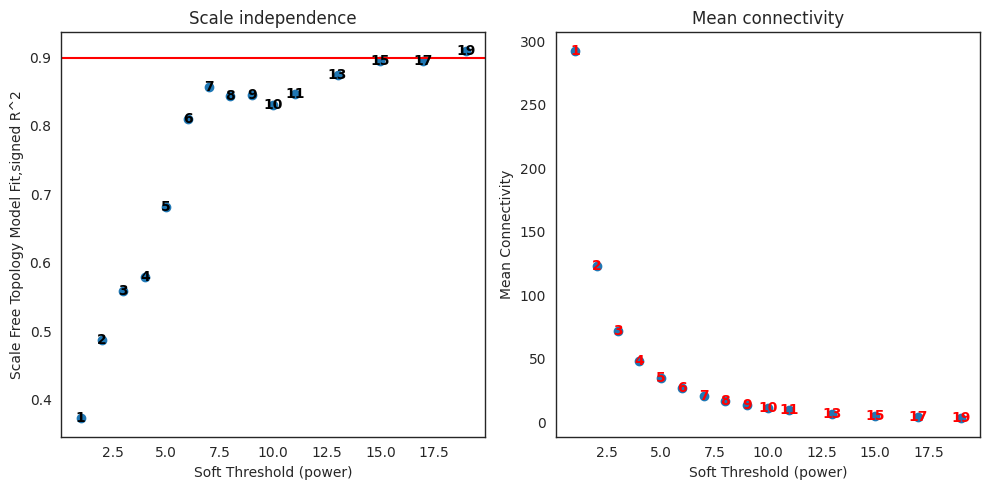

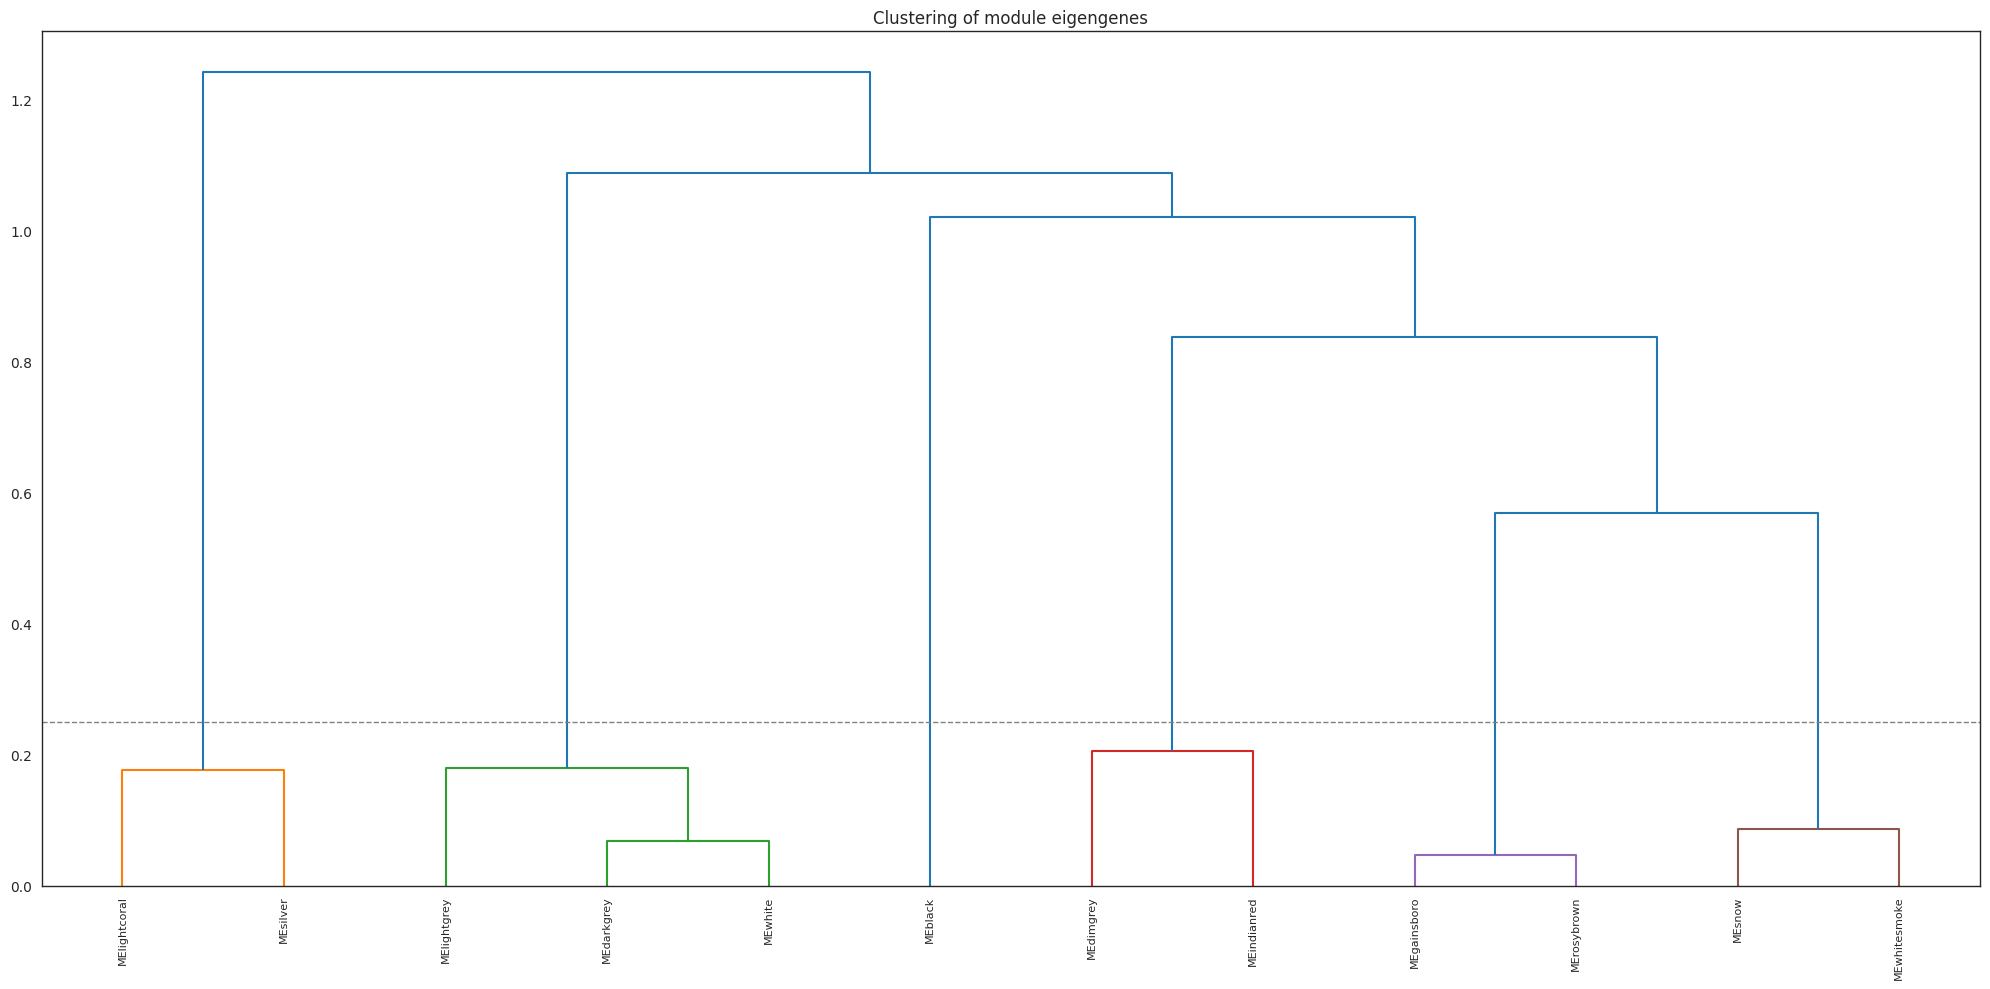

In [6]:
# Parche opcional: en scipy recientes rankdata(method="ordinal") devuelve float y PyWGCNA lo usa como indice.
import scipy.stats as _st, PyWGCNA.wgcna as _pw
_orig_rank = _st.rankdata
def _rank_int(*a, **k):
    r = _orig_rank(*a, **k)
    return r.astype(int) if k.get("method") == "ordinal" else r
_st.rankdata = _rank_int
_pw.rankdata = _rank_int

# R^2 >= 0.8 (umbral habitual) y parametros de modulos; findModules elige el power solo
pyWGCNA_5xFAD.RsquaredCut = 0.8
pyWGCNA_5xFAD.minModuleSize = 30
pyWGCNA_5xFAD.MEDissThres = 0.25
pyWGCNA_5xFAD.findModules()

modulos = pyWGCNA_5xFAD.datExpr.var["moduleColors"].value_counts()
print(f"\nPower elegido: {pyWGCNA_5xFAD.power}")
print(f"{len(modulos)} modulos detectados (incluido 'grey', los genes no asignados):")
print(modulos)


## 7. Añadir metadatos de muestras y de genes

Asignamos colores a los metadatos para las figuras, y añadimos el **símbolo de gen** a partir de la tabla local `geneList` (evita la consulta a BioMart).

In [7]:
import matplotlib as mpl

# Metadatos de las muestras
pyWGCNA_5xFAD.updateSampleInfo(path=str(DATA_DIR / "sampleInfo.csv"), sep=",")

# Edad como variable continua. analyseWGCNA() usa la ULTIMA columna de obs como barra de color continua,
# asi que Timepoint (numerica) debe ser la ultima.
obs = pyWGCNA_5xFAD.datExpr.obs
obs["Timepoint"] = obs["Age"].replace({"4mon": 4, "8mon": 8, "12mon": 12, "18mon": 18}).astype(int)

# Colores para las figuras
pyWGCNA_5xFAD.setMetadataColor("Sex", {"Female": "green", "Male": "gold"})
pyWGCNA_5xFAD.setMetadataColor("Genotype", {"5xFADWT": "darkviolet", "5xFADHEMI": "deeppink"})
pyWGCNA_5xFAD.setMetadataColor("Age", {"4mon": "lightblue", "8mon": "deepskyblue",
                                       "12mon": "steelblue", "18mon": "navy"})
pyWGCNA_5xFAD.setMetadataColor("Tissue", {"Cortex": "salmon", "Hippocampus": "seagreen"})
pyWGCNA_5xFAD.setMetadataColor("Timepoint", mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(4, 18), cmap="Blues"))

pyWGCNA_5xFAD.datExpr.obs.head()


,Age,Tissue,Sex,Genotype,Timepoint
sample_id,,,,,
X4mo_cortex_F_5xFADHEMI_430,4mon,Cortex,Female,5xFADHEMI,4
X4mo_cortex_F_5xFADHEMI_431,4mon,Cortex,Female,5xFADHEMI,4
X4mo_cortex_F_5xFADHEMI_433,4mon,Cortex,Female,5xFADHEMI,4
X4mo_cortex_F_5xFADHEMI_434,4mon,Cortex,Female,5xFADHEMI,4
X4mo_cortex_F_5xFADHEMI_511,4mon,Cortex,Female,5xFADHEMI,4


In [8]:
# Informacion de genes: Ensembl ID -> simbolo (tabla local)
# updateGeneInfo alinea por INDICE, asi que geneList debe estar indexada por gene_id
geneList = pd.read_csv(DATA_DIR / "geneList", sep=r"\s+")
geneList.index = geneList["gene_id"]
print(geneList.head())

pyWGCNA_5xFAD.updateGeneInfo(geneList)
print("Genes sin simbolo:", pyWGCNA_5xFAD.datExpr.var["gene_name"].isna().sum())
pyWGCNA_5xFAD.datExpr.var.head()


                               gene_id gene_name           trancript_id
gene_id                                                                
ENSMUSG00000000001  ENSMUSG00000000001     Gnai3   ENSMUSG00000000001.4
ENSMUSG00000000003  ENSMUSG00000000003      Pbsn  ENSMUSG00000000003.15
ENSMUSG00000000028  ENSMUSG00000000028     Cdc45  ENSMUSG00000000028.15
ENSMUSG00000000031  ENSMUSG00000000031       H19  ENSMUSG00000000031.16
ENSMUSG00000000037  ENSMUSG00000000037     Scml2  ENSMUSG00000000037.16
Genes sin simbolo: 0


,dynamicColors,moduleColors,moduleLabels,gene_id,gene_name,trancript_id
ENSMUSG00000064352,dimgrey,dimgrey,1.0,ENSMUSG00000064352,mt-Ts1,ENSMUSG00000064352.1
ENSMUSG00000105788,black,black,0.0,ENSMUSG00000105788,Gm47295,ENSMUSG00000105788.1
ENSMUSG00000102070,snow,snow,5.0,ENSMUSG00000102070,Gm28661,ENSMUSG00000102070.1
ENSMUSG00000064369,dimgrey,dimgrey,1.0,ENSMUSG00000064369,mt-Te,ENSMUSG00000064369.1
ENSMUSG00000064343,dimgrey,dimgrey,1.0,ENSMUSG00000064343,mt-Tq,ENSMUSG00000064343.1


## 8. Relación módulo–rasgo

`analyseWGCNA()` calcula, para cada módulo:

1. Su **eigengene** (primer componente principal del módulo)
2. La **correlación módulo–rasgo** con los metadatos (con p-valor)
3. La relación entre *module membership* y *gene significance*

El heatmap módulo × rasgo es la figura central de un WGCNA.

Analysing WGCNA...
Calculating module trait relationship ...
	Done..

Adding (signed) eigengene-based connectivity (module membership) ...
	Done..

plotting module heatmap eigengene...
	Done..

plotting module barplot eigengene...
	Done..

doing Enrichr GO analysis for each module...
GO directory does not exist!
Creating 5xFAD_GO directory!
	Done..



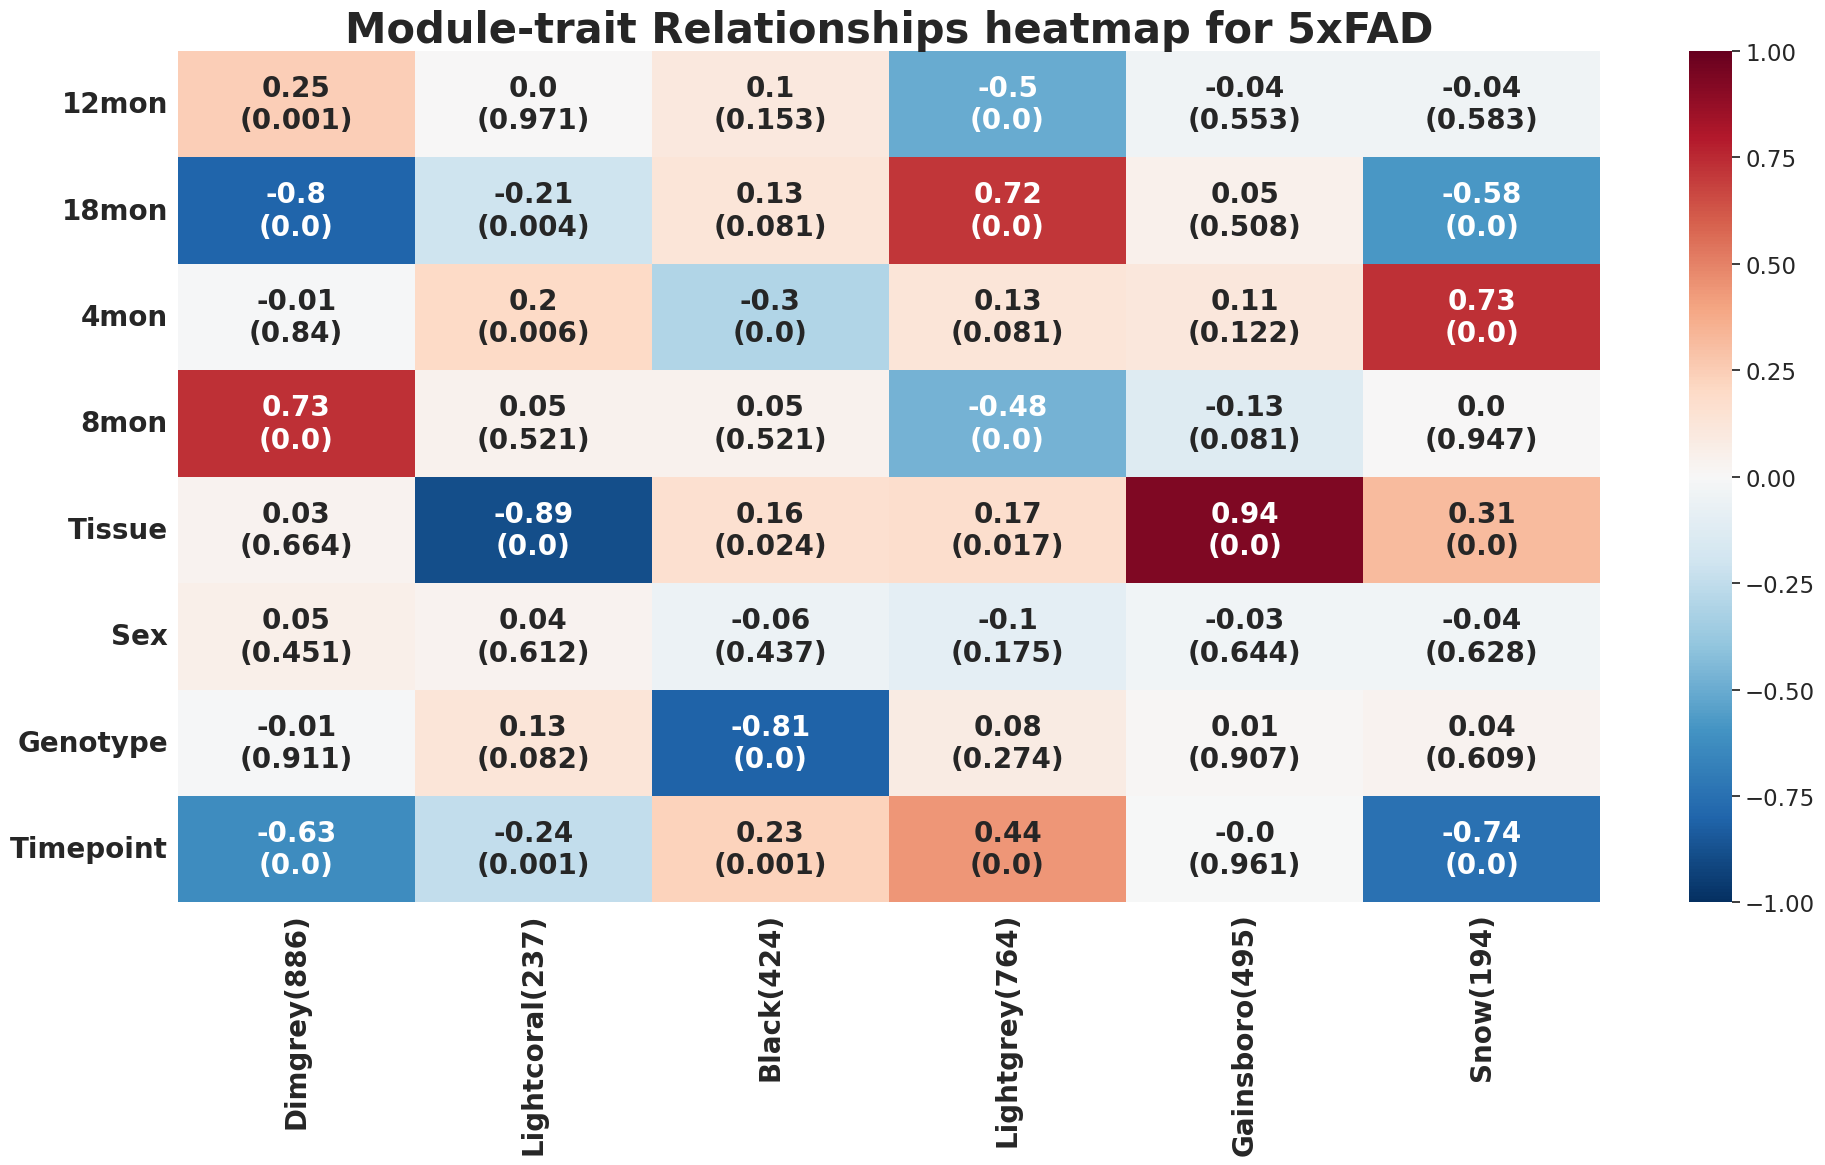













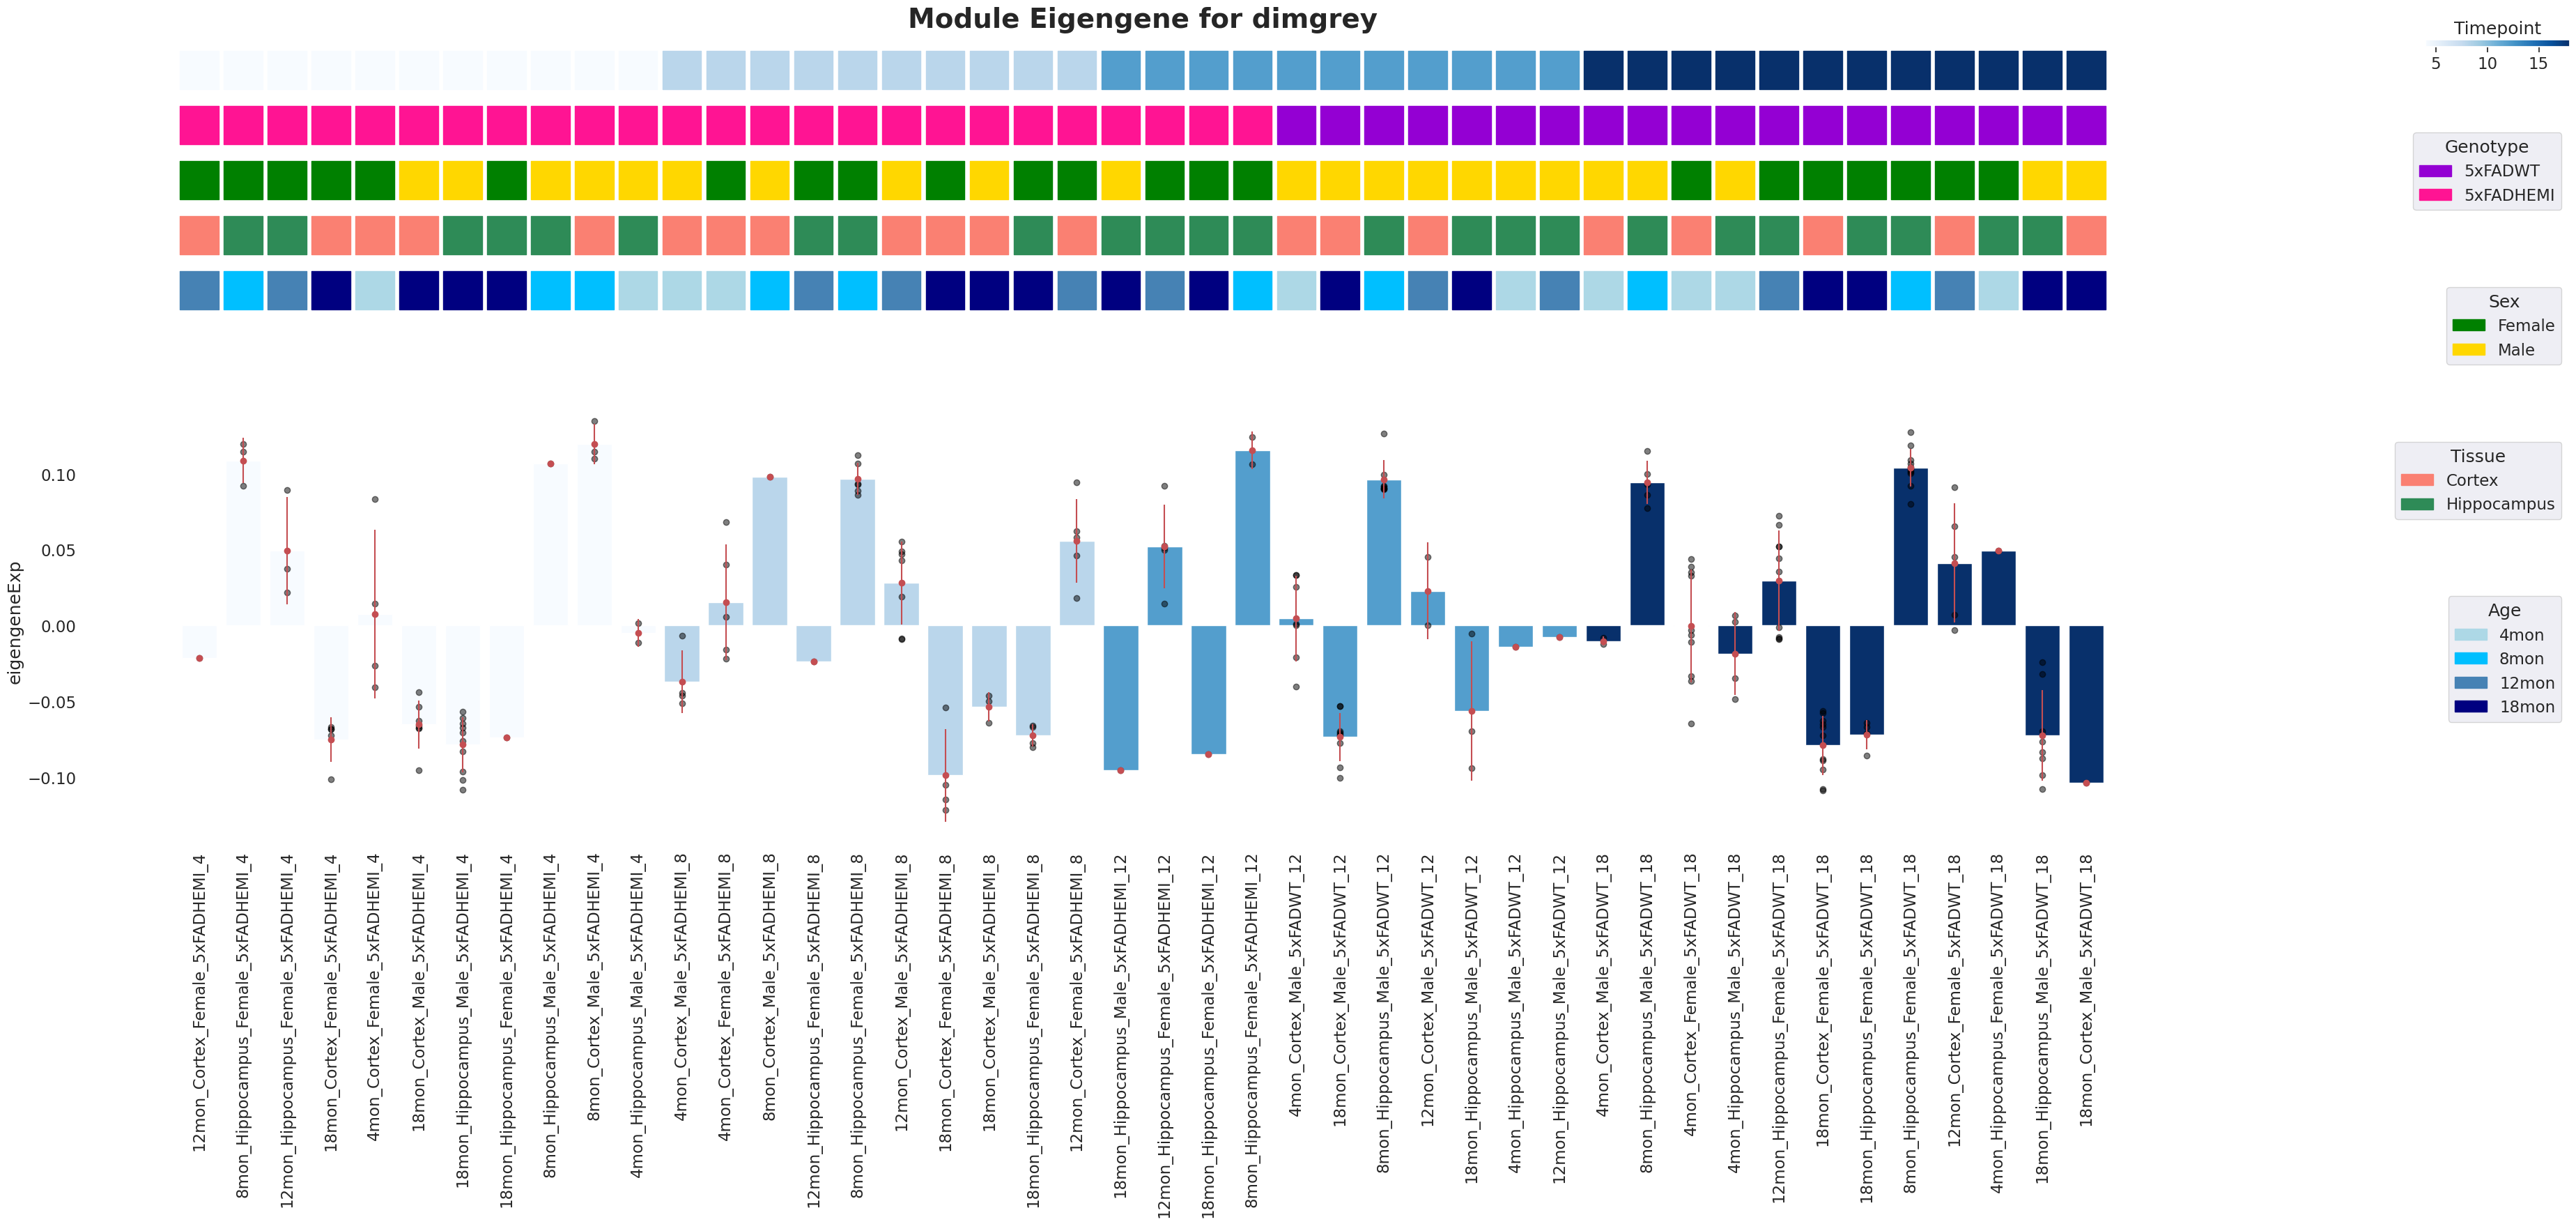

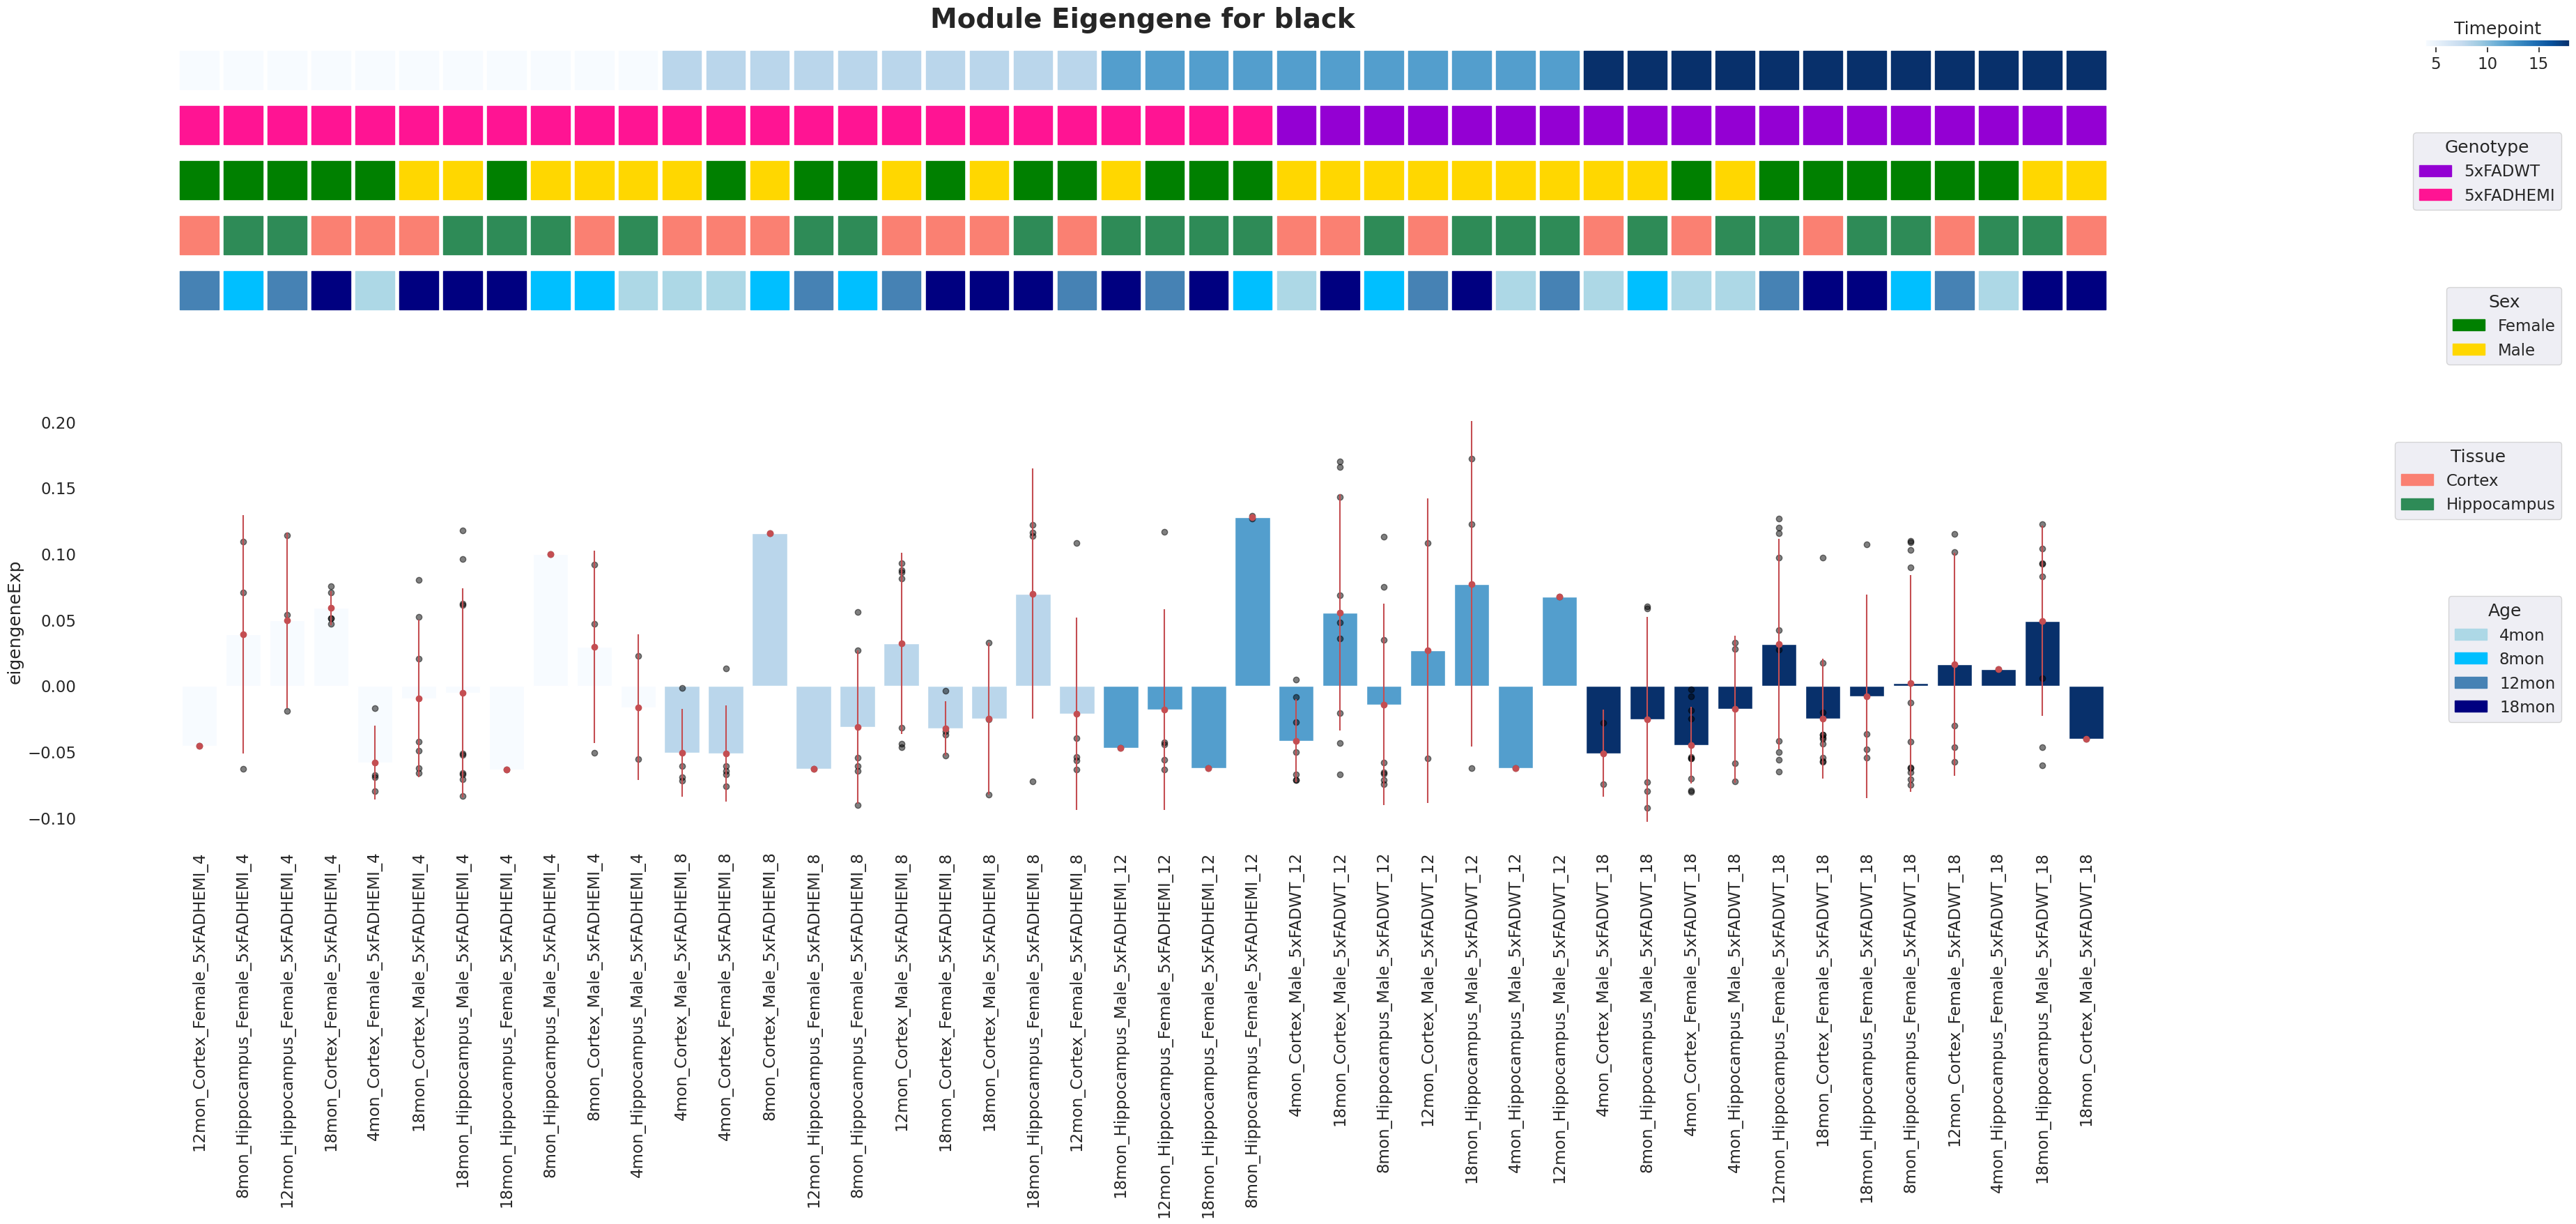

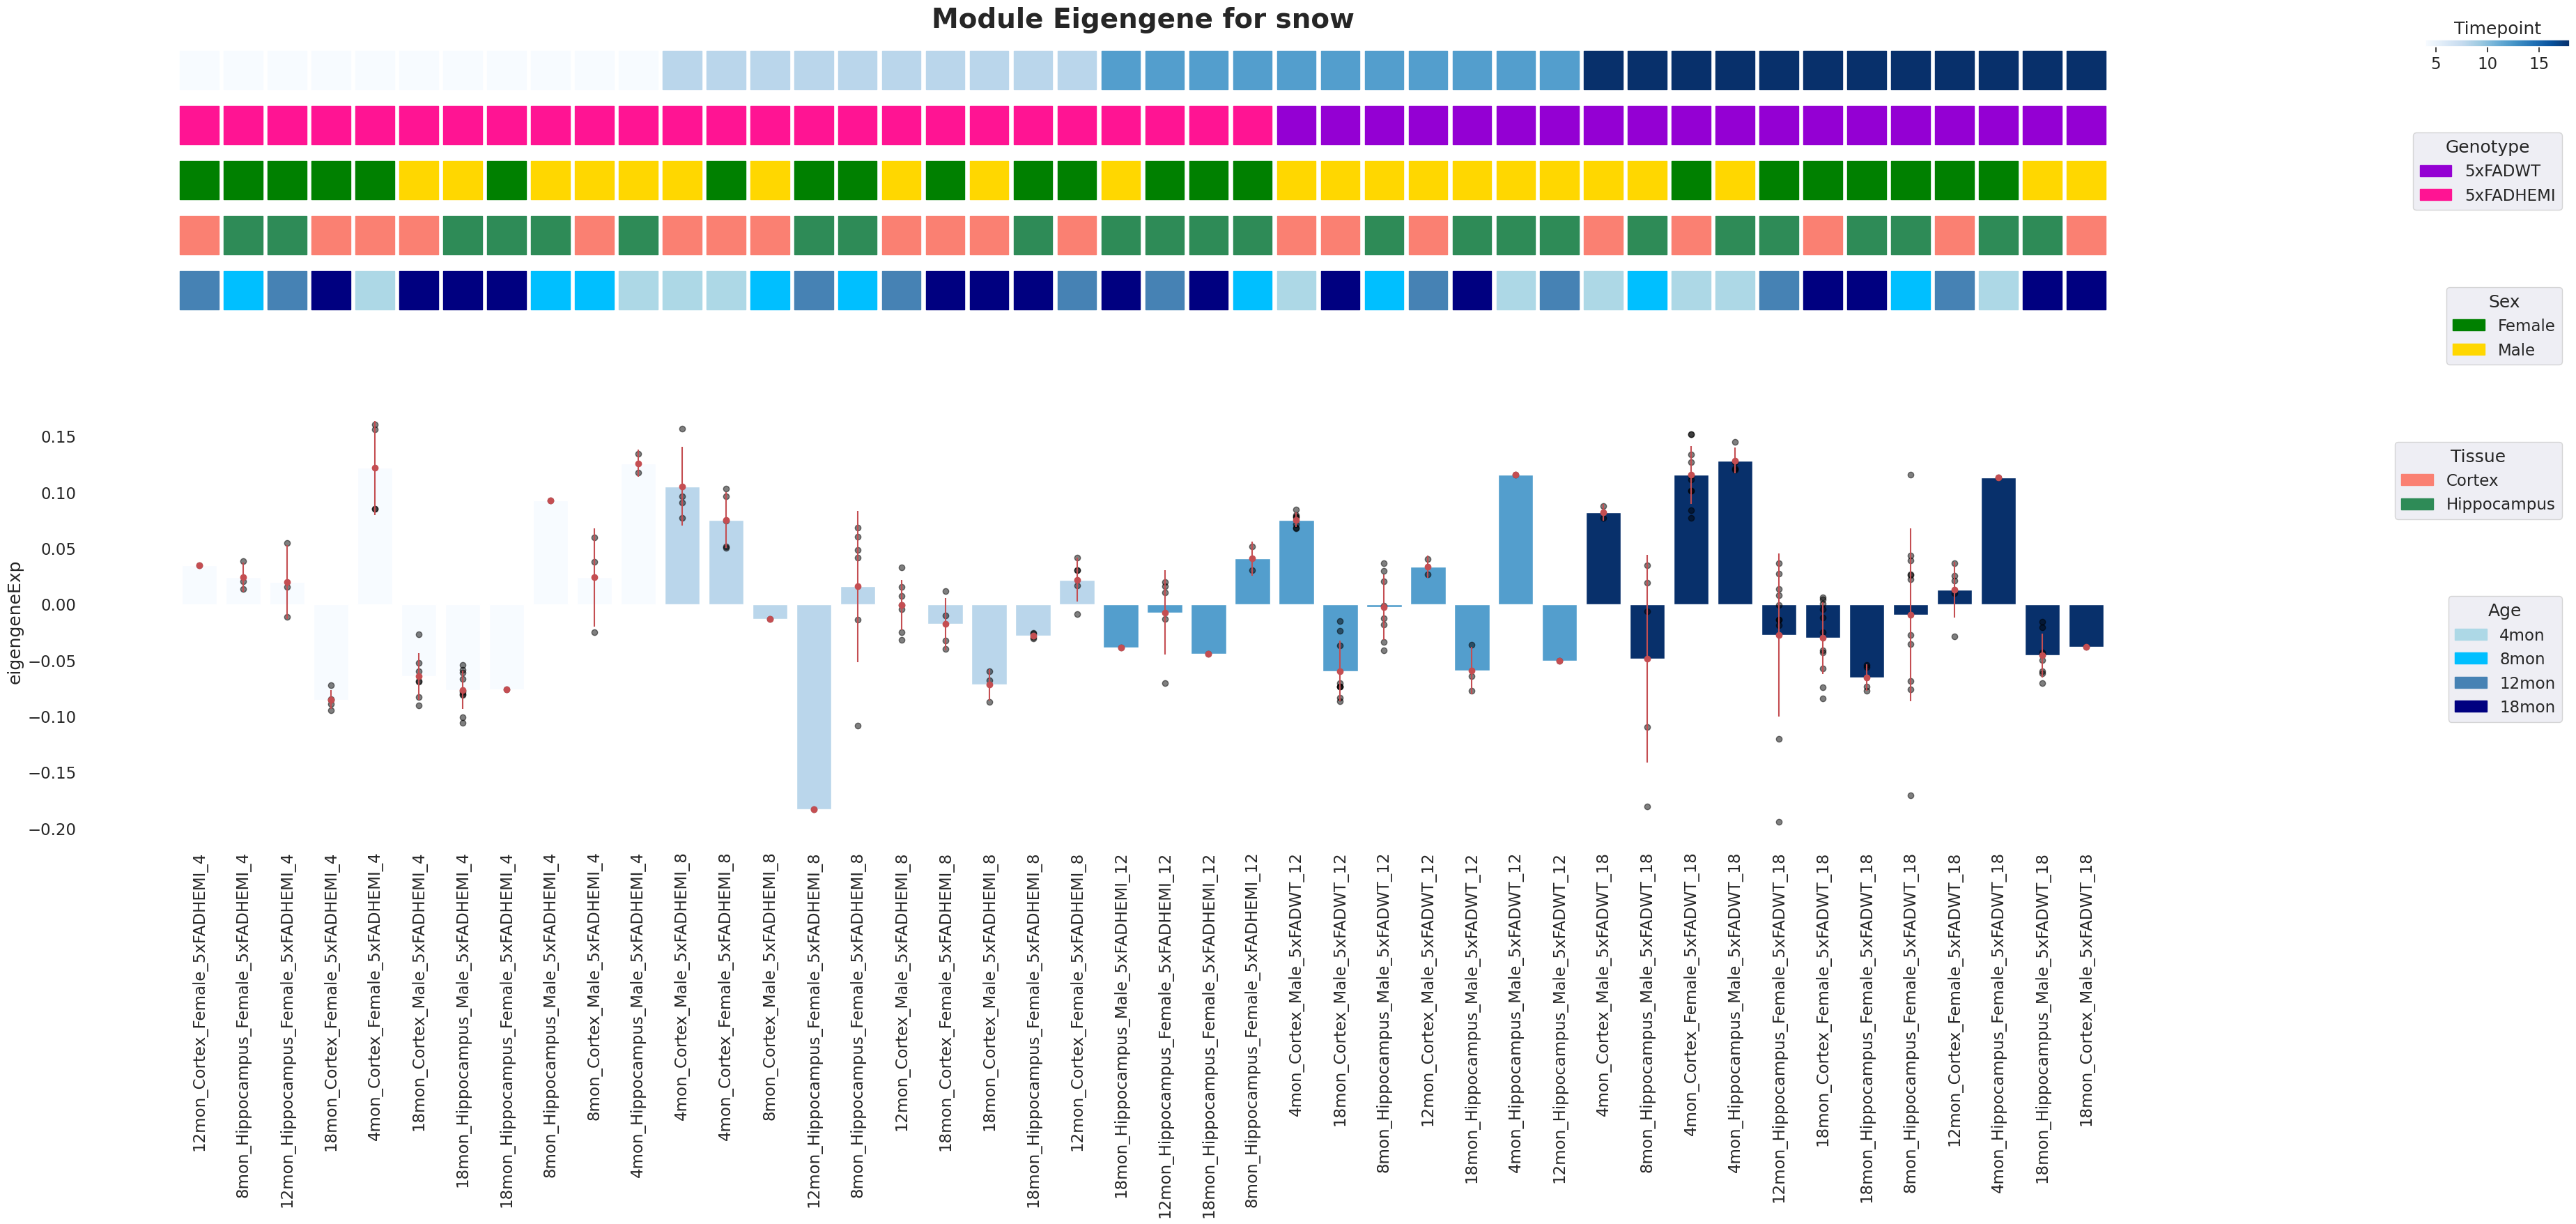

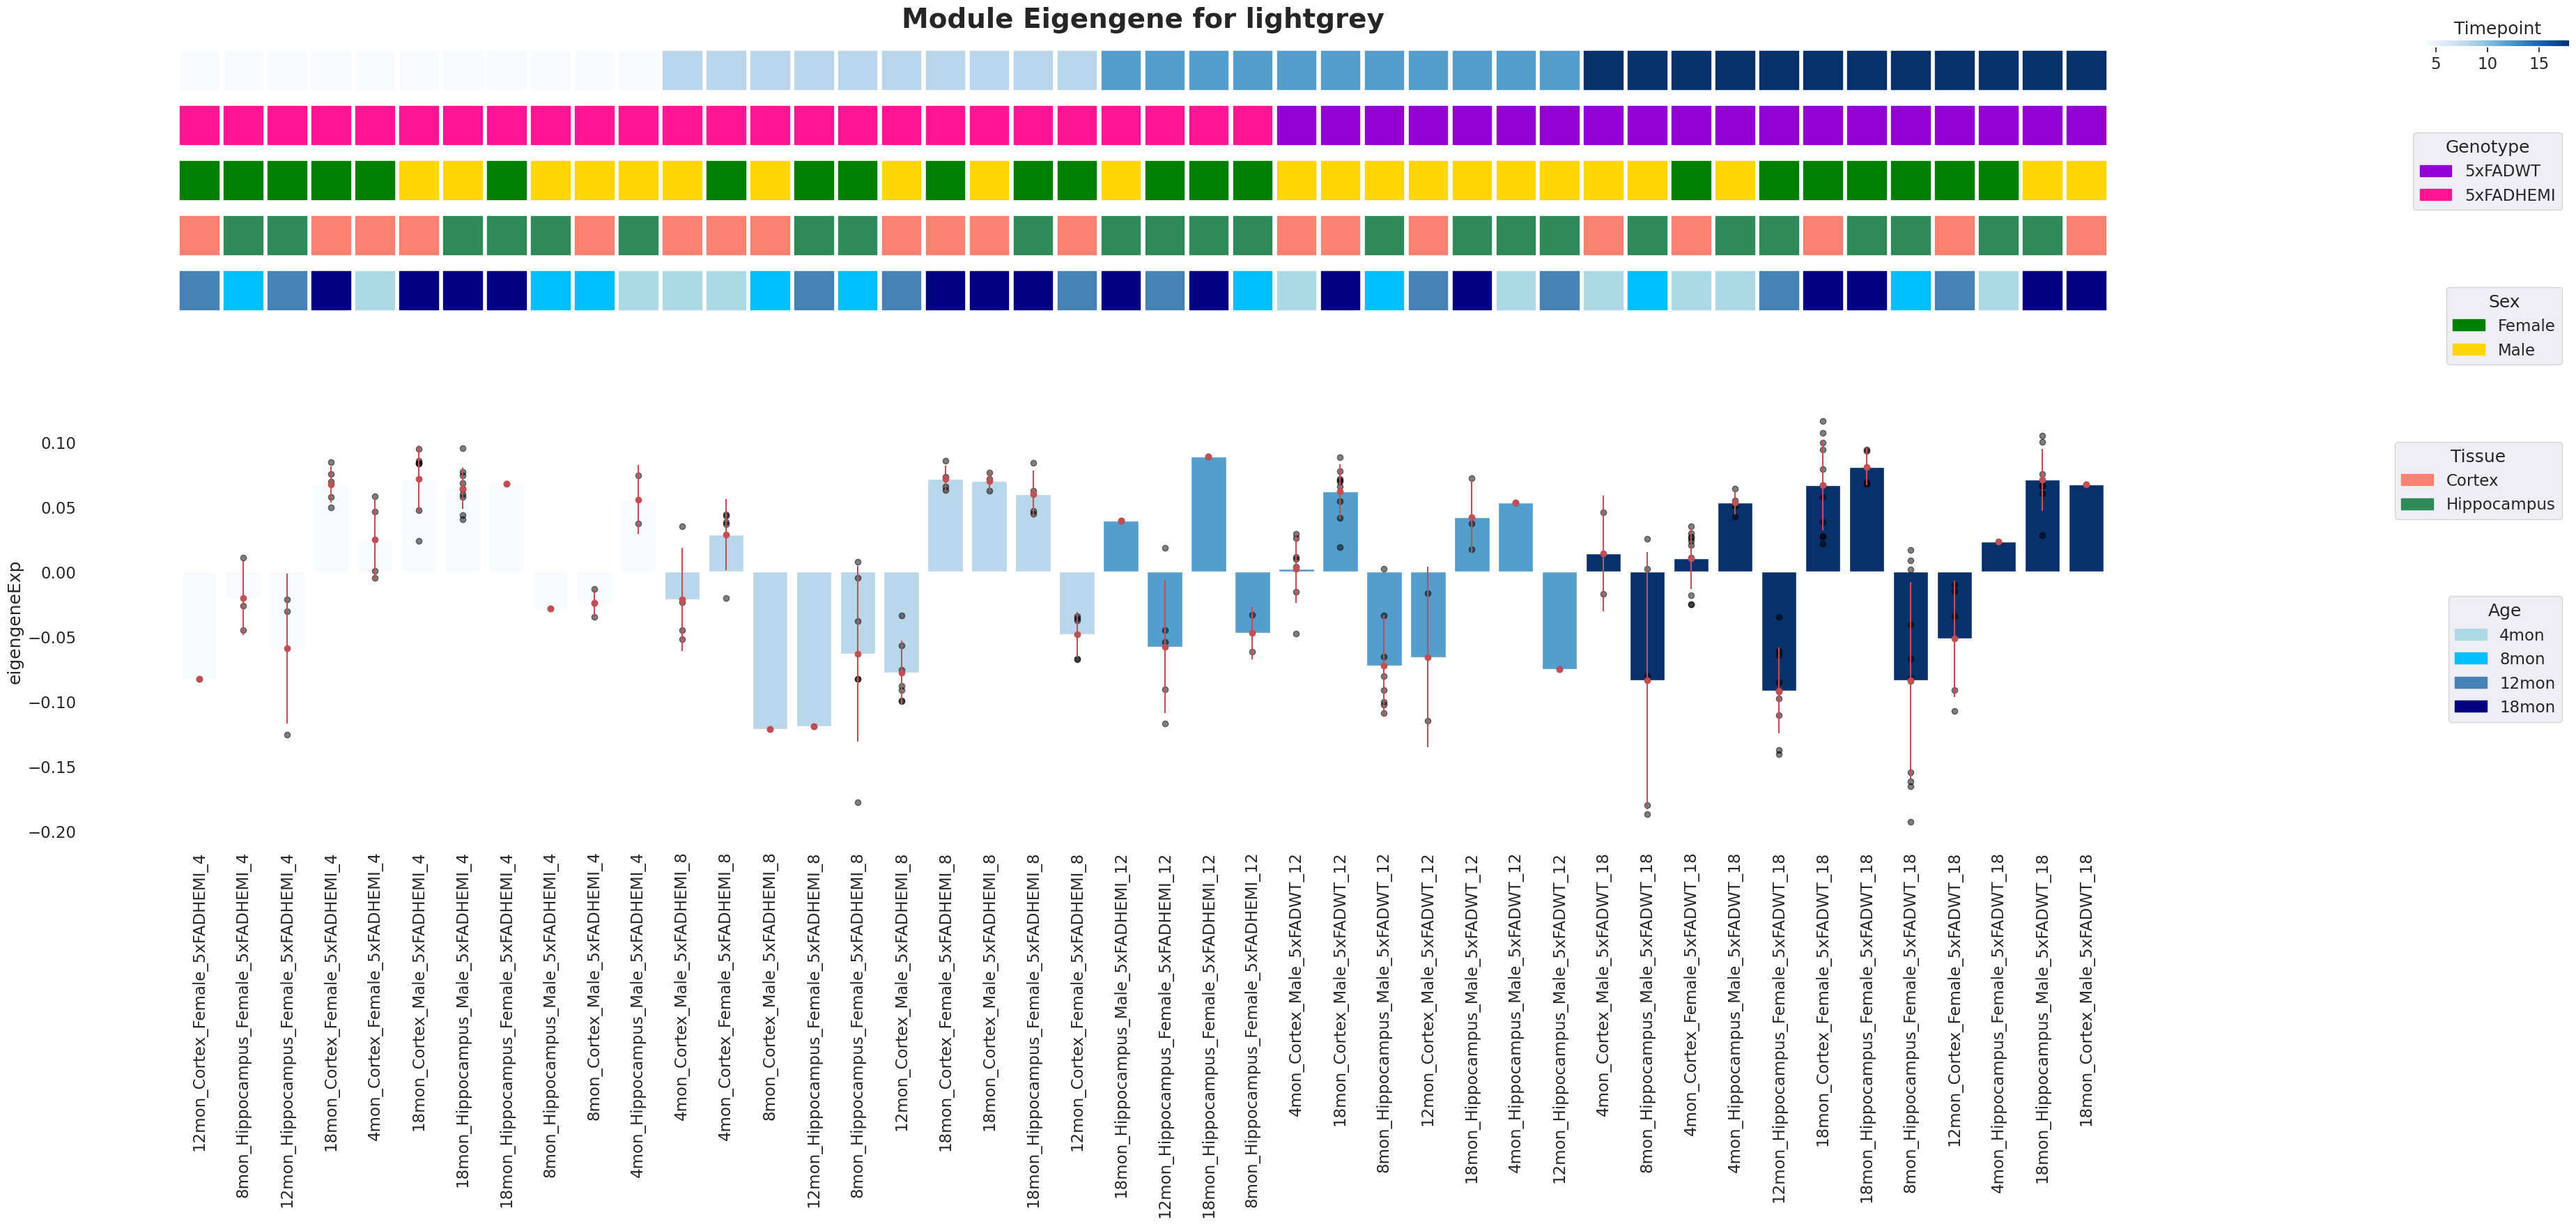

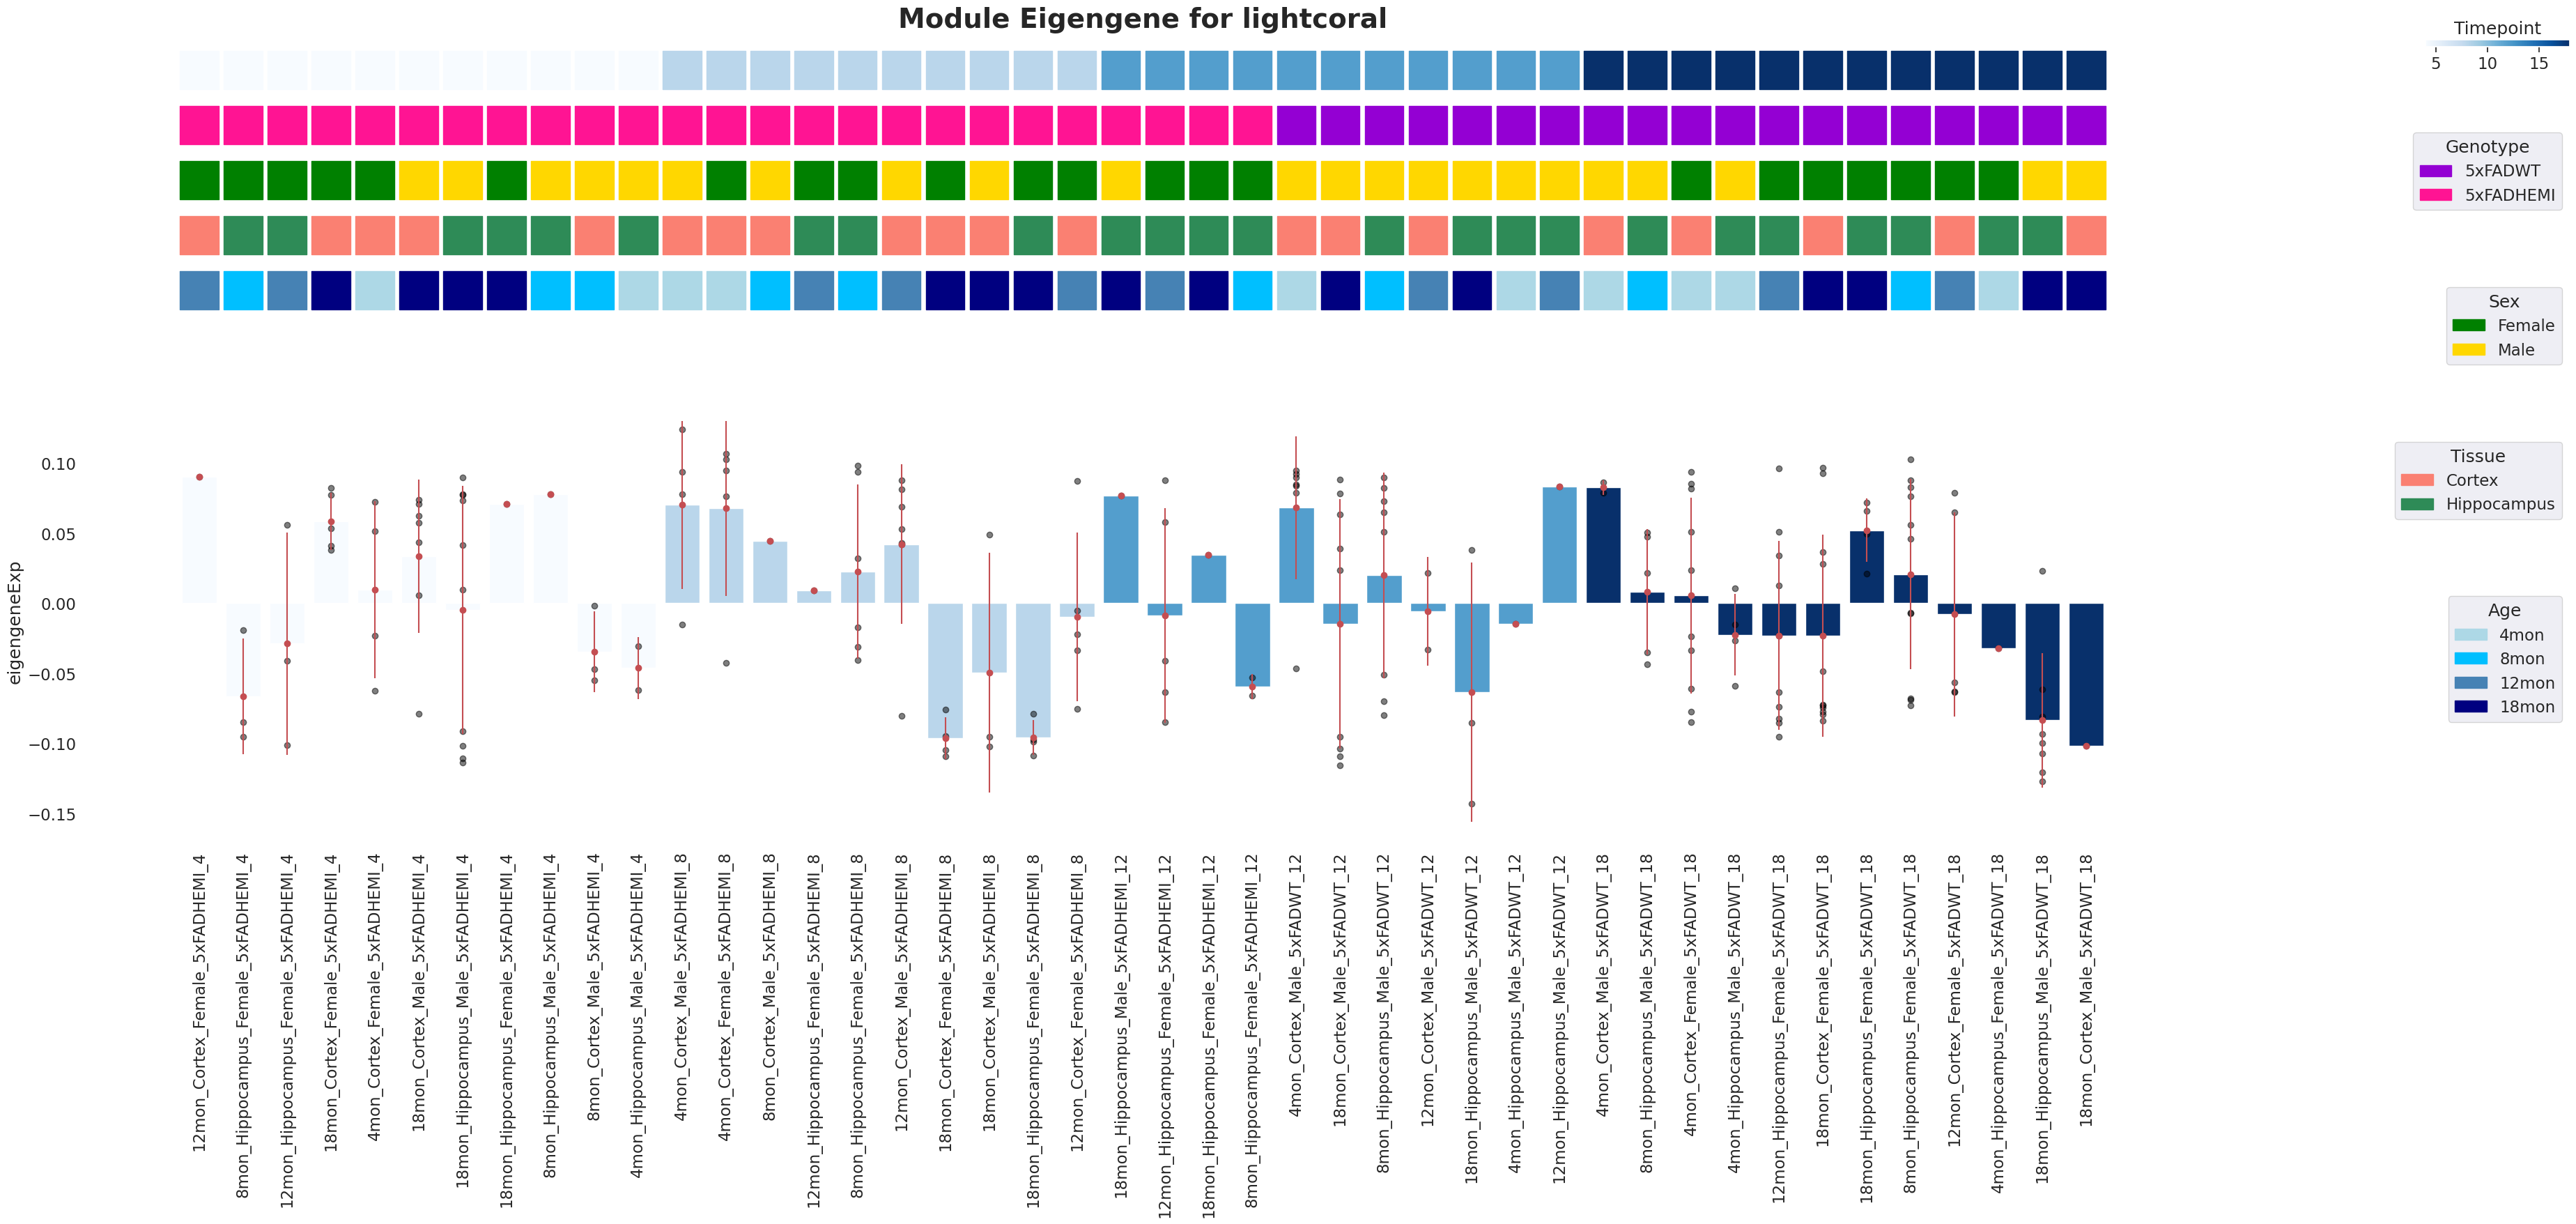

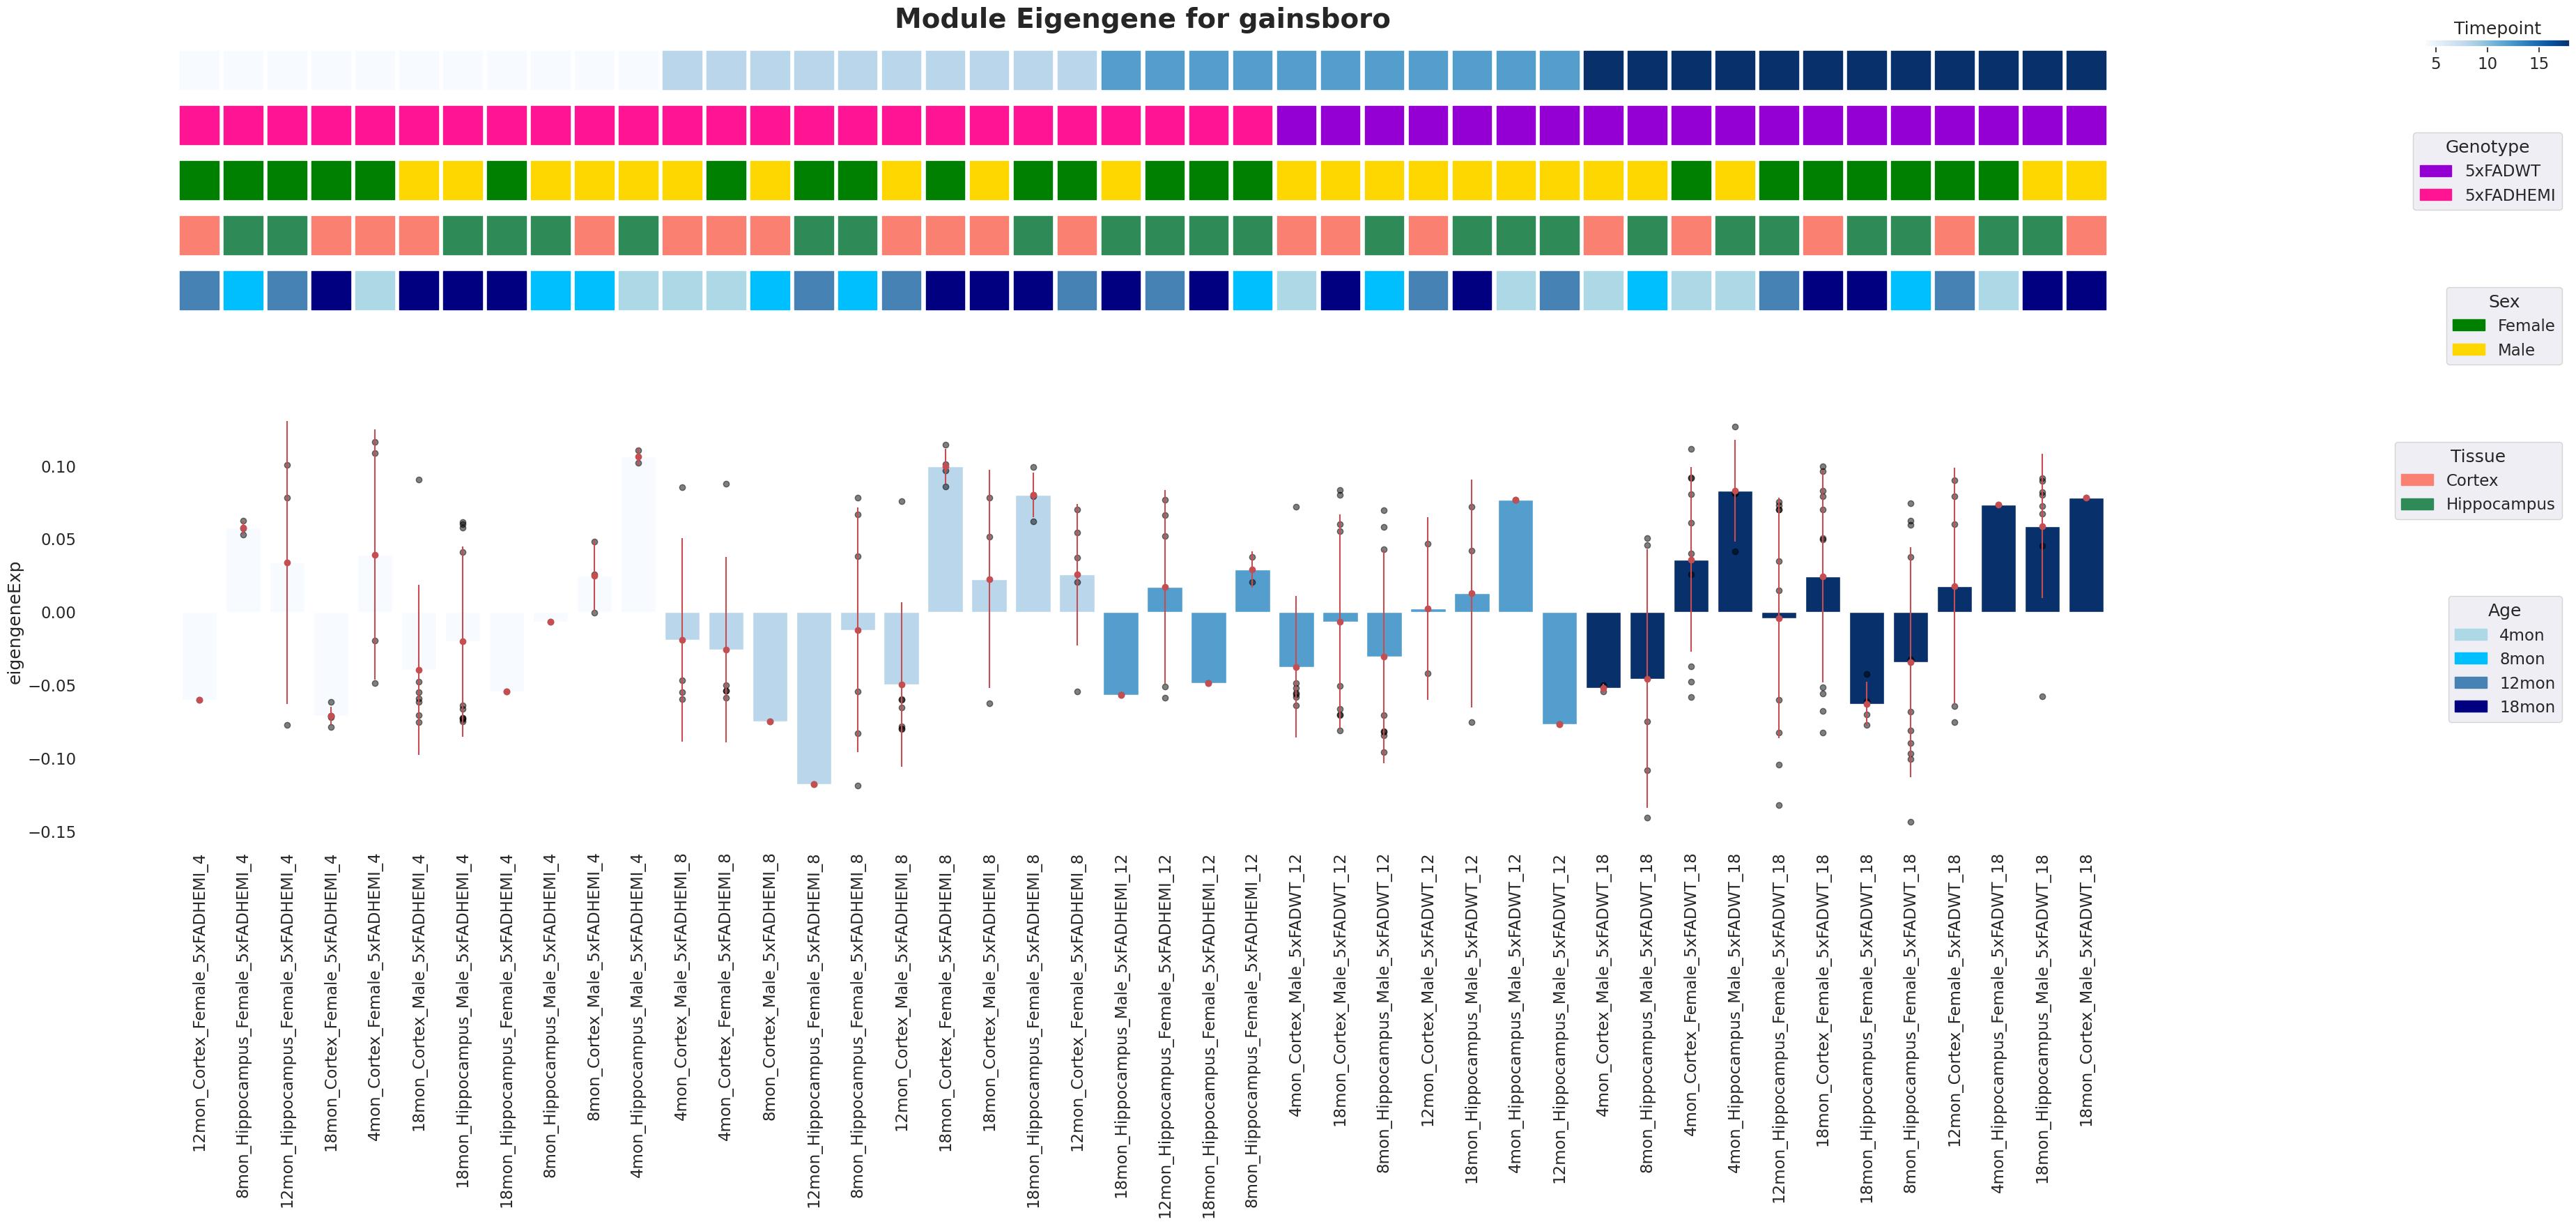

In [9]:
pyWGCNA_5xFAD.analyseWGCNA()

In [10]:
# Variable combinada edad x sexo (se crea despues de analyseWGCNA para no necesitar color propio)
obs = pyWGCNA_5xFAD.datExpr.obs
obs["Age_Sex"] = obs["Age"] + "_" + obs["Sex"]


### Explorando el heatmap módulo–rasgo

La función `module_trait_relationships_heatmap()` permite repetir el análisis con las variables que queramos.

**Truco**: si queremos ver la edad como una sola fila (correlación continua), la convertimos a numérica creando una columna `Timepoint`. También podemos crear variables combinadas, como `Age_Sex`.

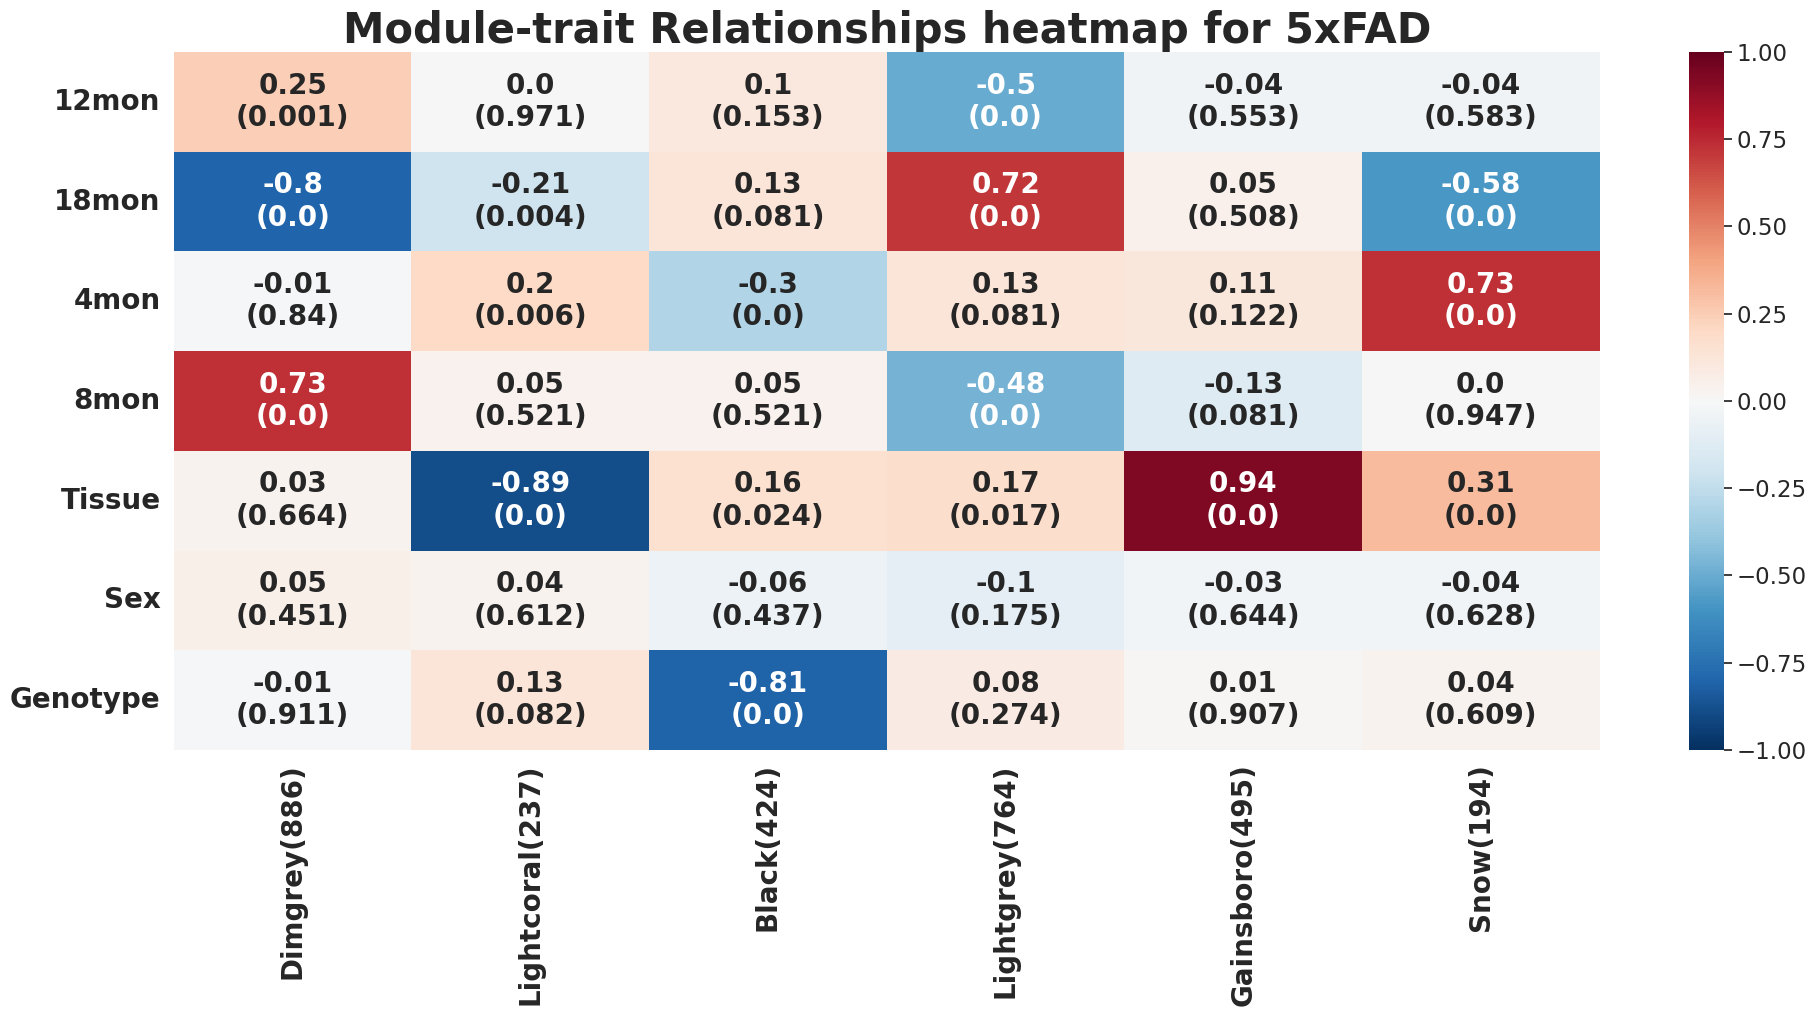

In [11]:
# Heatmap con todos los metadatos (cada categoría como columna dummy)
pyWGCNA_5xFAD.module_trait_relationships_heatmap(
    metaData=["Age", "Tissue", "Sex", "Genotype"],
    alternative="two-sided",
)

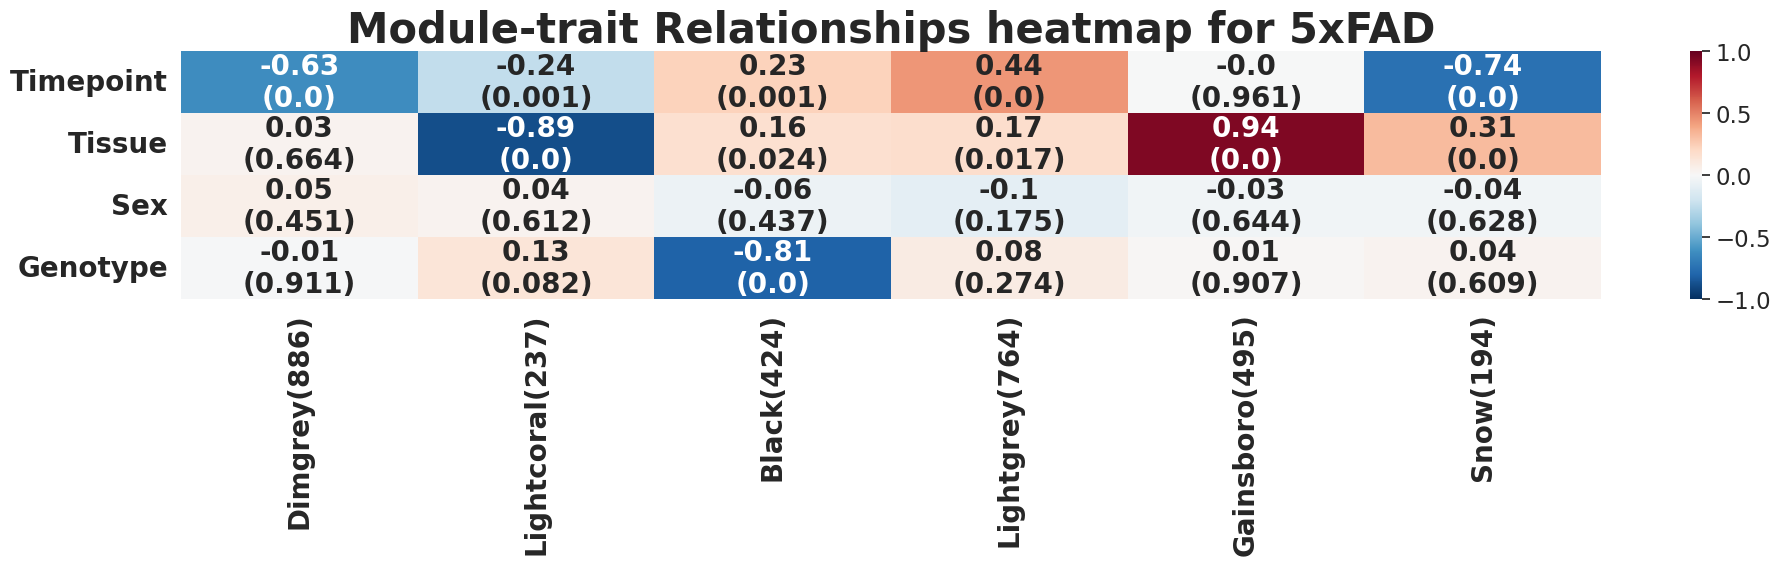

In [12]:
pyWGCNA_5xFAD.module_trait_relationships_heatmap(
    metaData=["Timepoint", "Tissue", "Sex", "Genotype"],
    alternative="two-sided",
)

> **Interpretación**: buscad los módulos con mayor correlación (positiva o negativa) con `Genotype_5xFADHEMI` (efecto de la enfermedad) y con `Timepoint` (progresión con la edad). ¿Coinciden?

## 9. Genes hub

Los **genes hub** son los más conectados dentro de cada módulo — candidatos a reguladores clave. `top_n_hub_genes()` los ordena por conectividad.

Elegimos automáticamente el **módulo más grande** (distinto de `grey`), pero cambiad `modulo_interes` por el módulo que más os interese del heatmap anterior (p. ej. el más correlacionado con el genotipo).

In [13]:
# Módulo de interés: el más grande (excluyendo 'grey', los no asignados)
todos = pyWGCNA_5xFAD.datExpr.var["moduleColors"]
modulos_validos = todos[todos != "grey"].value_counts()
modulo_interes = modulos_validos.index[0]
print("Módulos por tamaño:")
print(modulos_validos)
print(f"\nMódulo de interés: {modulo_interes} ({modulos_validos.iloc[0]} genes)")
print("→ Cambiad 'modulo_interes' por el módulo que queráis explorar.")

Módulos por tamaño:
moduleColors
dimgrey       886
lightgrey     764
gainsboro     495
black         424
lightcoral    237
snow          194
Name: count, dtype: int64

Módulo de interés: dimgrey (886 genes)
→ Cambiad 'modulo_interes' por el módulo que queráis explorar.


In [14]:
hub = pyWGCNA_5xFAD.top_n_hub_genes(moduleName=modulo_interes, n=20)
cols = [c for c in ["gene_name", "moduleColors", "kME", "connectivity"] if c in hub.columns]
hub[cols].head(20) if cols else hub.head(20)

calculating adjacency matrix ...
	Done..



,gene_name,moduleColors,connectivity
ENSMUSG00000064338,mt-Tv,dimgrey,13.197447
ENSMUSG00000064344,mt-Tm,dimgrey,13.149326
ENSMUSG00000064352,mt-Ts1,dimgrey,13.067832
ENSMUSG00000064369,mt-Te,dimgrey,13.006119
ENSMUSG00000064347,mt-Ta,dimgrey,12.964274
ENSMUSG00000064336,mt-Tf,dimgrey,11.925714
ENSMUSG00000064359,mt-Tg,dimgrey,11.883299
ENSMUSG00000064353,mt-Td,dimgrey,11.281856
ENSMUSG00000047230,Cldn2,dimgrey,10.597381
ENSMUSG00000015652,Steap1,dimgrey,10.547958


## 10. Visualización de la red de coexpresión

`CoexpressionModulePlot()` dibuja la red de un módulo (o de varios, mostrando las conexiones entre ellos). Los nodos más grandes/centrales suelen ser los genes hub.

> Las figuras se guardan en `PyWGCNA_output/figures/` y se muestran en pantalla.

In [15]:
# Red del módulo de interés (top genes y conexiones)
pyWGCNA_5xFAD.CoexpressionModulePlot(
    modules=[modulo_interes],
    numGenes=20,
    numConnections=100,
    minTOM=0,
)

# pyvis guarda la red como HTML interactivo; la mostramos dentro del notebook
from IPython.display import HTML
HTML(filename=f"PyWGCNA_output/figures/network/{modulo_interes}.html")

Network directory does not exist!
Creating network directory!


In [16]:
# Red con varios módulos para ver sus interconexiones
top_modulos = modulos_validos.index[:4].tolist()
print("Módulos representados:", top_modulos)
pyWGCNA_5xFAD.CoexpressionModulePlot(
    modules=top_modulos,
    numGenes=40,
    numConnections=400,
    minTOM=0,
    file_name="top_modulos",
)
HTML(filename="PyWGCNA_output/figures/network/top_modulos.html")

Módulos representados: ['dimgrey', 'lightgrey', 'gainsboro', 'black']


## 11. Enriquecimiento funcional de los módulos

`functional_enrichment_analysis()` lanza un ORA (vía Enrichr/gseapy) sobre los genes de un módulo, igual que hicimos en la práctica 5. Usamos librerías de ratón:

- **GO**: `GO_Biological_Process_2021` (+ CC y MF)
- **KEGG**: `KEGG_2019_Mouse`
- **Reactome**

> Necesita conexión a internet (consulta Enrichr).

In [17]:
pyWGCNA_5xFAD.figureType = "png"

# Gene Ontology
pyWGCNA_5xFAD.functional_enrichment_analysis(
    type="GO",
    moduleName=modulo_interes,
    sets=["GO_Biological_Process_2021",
          "GO_Cellular_Component_2021",
          "GO_Molecular_Function_2021"],
    p_value=0.05,
)

No enrich terms when cutoff = 0.05 in module dimgrey


In [18]:
# KEGG (ratón)
pyWGCNA_5xFAD.functional_enrichment_analysis(
    type="KEGG",
    moduleName=modulo_interes,
    sets=["KEGG_2019_Mouse"],
    p_value=0.05,
)

KEGG directory does not exist!
Creating 5xFAD_KEGG directory!
No enrich terms when cutoff = 0.05 in module dimgrey


## 12. Interacciones proteína–proteína (STRING)

Con `request_PPI()` recuperamos de **STRING** las interacciones conocidas entre los genes de un módulo, y con `PPI_network()` las dibujamos como red. `species=10090` es el código NCBI de *Mus musculus*.

> Necesita conexión a internet (consulta STRING).

In [19]:
# PPIs conocidas entre los genes del módulo de interés
# Usar los top hub genes del módulo para evitar errores de URL muy larga en STRING
hub_genes = pyWGCNA_5xFAD.top_n_hub_genes(moduleName=modulo_interes, n=50)
genes_modulo = hub_genes["gene_name"].dropna().tolist() if "gene_name" in hub_genes else hub_genes.index.tolist()
print(f"Genes a consultar en STRING: {len(genes_modulo)}")

PPI = pyWGCNA_5xFAD.request_PPI(genes=genes_modulo, species=10090)
print(f"Interacciones encontradas: {len(PPI)}")
PPI.head(10)

calculating adjacency matrix ...
	Done..

Genes a consultar en STRING: 50
16 genes out of 50 genes have PPI.
Interacciones encontradas: 80


,gene1,gene2,score
0,Aqp1,Aqp12,0.951
1,Aqp1,Aqp11,0.948
2,Aqp1,Ctnnb1,0.845
3,Aqp1,Aqp7,0.78
4,Aqp1,Aqp9,0.779
5,Steap1,Steap2,0.883
6,Steap1,Slc11a2,0.616
7,Steap1,Psca,0.57
8,Steap1,Cybrd1,0.555
9,Steap1,Triap1,0.554


In [20]:
# Red PPI con los genes más conectados
top_genes_ppi = PPI.gene1.value_counts().head(20).index.tolist()
pyWGCNA_5xFAD.PPI_network(species=10090, geneList=top_genes_ppi)

PPI directory does not exist!
Creating PPI directory!
16 genes out of 16 genes have PPI.
Saving interaction network to PyWGCNA_output/figures/PPI/Aqp1_PPI.png
For having interactive network, click line below:
https://string-db.org/api/tsv/get_link?identifiers=Aqp12%0dAqp11%0dCtnnb1%0dAqp7%0dAqp9%0dAqp1&species=10090
Saving interaction network to PyWGCNA_output/figures/PPI/Ccdc135_PPI.png
For having interactive network, click line below:
https://string-db.org/api/tsv/get_link?identifiers=Iqcg%0dGas8%0dLrrc48%0dAnkdd1a%0dSowahd%0dCcdc135&species=10090
Saving interaction network to PyWGCNA_output/figures/PPI/Cldn2_PPI.png
For having interactive network, click line below:
https://string-db.org/api/tsv/get_link?identifiers=Tjp2%0dCldn12%0dTjp1%0dOcln%0dTjp3%0dCldn2&species=10090
Saving interaction network to PyWGCNA_output/figures/PPI/Col8a1_PPI.png
For having interactive network, click line below:
https://string-db.org/api/tsv/get_link?identifiers=Lepre1%0dCol8a2%0dP4ha3%0dP4ha2%0dP4ha1%0d

,gene1,gene2,score
0,Aqp1,Aqp12,0.951
1,Aqp1,Aqp11,0.948
2,Aqp1,Ctnnb1,0.845
3,Aqp1,Aqp7,0.78
4,Aqp1,Aqp9,0.779
...,...,...,...
46,Wdr86,Skp1a,0.76
45,Wdr86,Crygn,0.775
49,Wdr86,Cacul1,0.575
47,Wdr86,Prkag2,0.687


## 13. Guardar y descargar resultados

Guardamos el objeto PyWGCNA completo (se puede recargar con `PyWGCNA.readWGCNA("5xFAD.p")` sin repetir el análisis) y empaquetamos todas las figuras y tablas.

In [21]:
import shutil
from google.colab import files

# Guardar el objeto completo
pyWGCNA_5xFAD.saveWGCNA()

# Empaquetar resultados (figuras + tablas + objeto)
zip_path = shutil.make_archive("resultados_WGCNA_5xFAD", "zip", "PyWGCNA_output")
print(f"ZIP creado: {zip_path}")
files.download(zip_path)

Saving WGCNA as 5xFAD.p
ZIP creado: /content/resultados_WGCNA_5xFAD.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Preguntas de reflexión

1. **Soft power**: ¿qué β eligió `findModules()` y por qué? ¿Qué pasaría con un β demasiado bajo o demasiado alto?
2. **Módulo–rasgo**: ¿qué módulos se asocian al genotipo 5xFADHEMI? ¿Y a la edad (`Timepoint`)? ¿Son los mismos? ¿Qué implicaría biológicamente?
3. **Tejido y sexo**: ¿hay módulos específicos de tejido o de sexo? ¿Cómo lo comprobaríais con la variable combinada `Age_Sex`?
4. **Genes hub**: mirad los genes hub del módulo más asociado al genotipo. ¿Conocéis alguno relacionado con la enfermedad de Alzheimer?
5. **Enriquecimiento**: ¿qué procesos biológicos dominan el módulo de interés? ¿Encajan con la patología (inflamación, sinapsis, metabolismo amiloide…)?
6. **WGCNA vs expresión diferencial**: ¿qué ventajas y limitaciones tiene el análisis por módulos frente al análisis gen a gen de las prácticas anteriores?

---

**Entrega**: el notebook ejecutado (o script `.py`) + un PDF con las figuras clave y las respuestas a las preguntas.